# Laboratorium 3 — analiza koszyka zakupowego
**Cel:** odkryć reguły asocjacyjne i przełożyć je na decyzje biznesowe.

## 0. Zasada pracy
Nie szukamy „największej liczby”. Szukamy reguły, która jest jednocześnie statystycznie sensowna, biznesowo użyteczna i możliwa do przetestowania.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from apriori_local import make_basket_matrix, apriori, association_rules, pretty_set
pd.set_option('display.max_colwidth', 100)

## 1. Wczytanie i kontrola danych

In [ ]:
transactions = pd.read_csv('transakcje_marketbasket_lab3.csv')
products = pd.read_csv('produkty_lab3.csv')

# pierwsze wiersze, rozmiar danych i typy kolumn
display(transactions.head(5), products.head(5))
print("Transakcje:", transactions.shape, "| produkty:", products.shape)
print(transactions.dtypes)
print(products.dtypes)
print("Braki danych:", transactions.isna().sum().sum())

,transaction_id,transaction_datetime,channel,product_id,product_name,quantity
0,T00001,2026-03-11 10:05:00,Wrocław Centrum,P008,banany,1
1,T00001,2026-03-11 10:05:00,Wrocław Centrum,P005,kawa,1
2,T00001,2026-03-11 10:05:00,Wrocław Centrum,P001,mleko,1
3,T00001,2026-03-11 10:05:00,Wrocław Centrum,P024,pizza mrożona,1
4,T00001,2026-03-11 10:05:00,Wrocław Centrum,P011,płatki śniadaniowe,1


,product_id,product_name,category,margin_pct
0,P001,mleko,nabiał,18.0
1,P002,pieczywo,pieczywo,28.0
2,P003,jajka,nabiał,22.0
3,P004,masło,nabiał,24.0
4,P005,kawa,napoje,35.0


Transakcje: (4249, 6) | produkty: (30, 4)
transaction_id            str
transaction_datetime      str
channel                   str
product_id                str
product_name              str
quantity                int64
dtype: object
product_id          str
product_name        str
category            str
margin_pct      float64
dtype: object
Braki danych: 0


In [ ]:
# unikalne transakcje, produkty i kanały
ids = transactions["transaction_id"]
produkty = transactions["product_name"]
kanaly = transactions["channel"]
print("Transakcje:", ids.nunique(), "| produkty:", produkty.nunique(), "| kanały:", kanaly.nunique())

# liczba pozycji to nie liczba paragonów
print("Pozycje wg kanału:", kanaly.value_counts().to_dict())
print("Paragony wg kanału:", transactions.groupby("channel")["transaction_id"].nunique().to_dict())

# czy produkt powtarza się w jednej transakcji
powtorzenia = transactions.duplicated(["transaction_id", "product_name"]).sum()
print("Powtórzone pary transakcja-produkt:", powtorzenia)
print("Pozycje z ilością > 1:", (transactions["quantity"] > 1).sum())

Transakcje: 1000 | produkty: 30 | kanały: 4
Pozycje wg kanału: {'Online': 1254, 'Wrocław Centrum': 1236, 'Wrocław Północ': 982, 'Wrocław Południe': 777}
Paragony wg kanału: {'Online': 297, 'Wrocław Centrum': 287, 'Wrocław Południe': 190, 'Wrocław Północ': 226}
Powtórzone pary transakcja-produkt: 0
Pozycje z ilością > 1: 100


## 2. Wielkość koszyka

count    1000.000000
mean        4.249000
std         2.046262
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max        14.000000
Name: product_name, dtype: float64


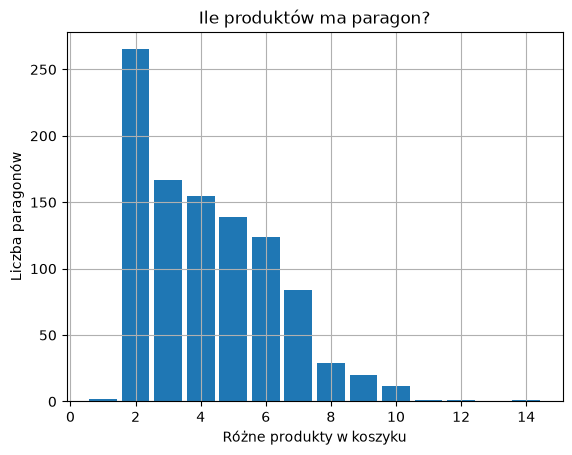

In [ ]:
# liczba różnych produktów w każdej transakcji
liczby_produktow = transactions.groupby("transaction_id")["product_name"].nunique()

# mediana (50%), średnia, minimum i maksimum
print(liczby_produktow.describe())

# granice połówkowe: każda liczba produktów ma osobny słupek
granice = [x + 0.5 for x in range(liczby_produktow.max() + 1)]
ax = liczby_produktow.hist(bins=granice, rwidth=0.85)
ax.set_title("Ile produktów ma paragon?")
ax.set_xlabel("Różne produkty w koszyku")
ax.set_ylabel("Liczba paragonów")
plt.show()

## 3. Macierz transakcja–produkt

In [ ]:
basket = make_basket_matrix(transactions)

# wymiar, zgodność z danymi, wartości 0/1 i udział jedynek
ile_paragonow, ile_towarow = basket.shape
gestosc = basket.to_numpy().mean()
print("Wymiar:", ile_paragonow, "x", ile_towarow)
print("Zgodny z danymi:", basket.shape == (ids.nunique(), produkty.nunique()))
print("Tylko 0 i 1:", basket.isin([0, 1]).all().all())
print("Gęstość:", round(gestosc, 3))
basket.head()

Wymiar: 1000 x 30
Zgodny z danymi: True
Tylko 0 i 1: True
Gęstość: 0.142


product_name,banany,chipsy,chusteczki nawilżane,cola,cukier,detergent,herbata,jabłka,jajka,jogurt,...,pieluchy,piwo,pizza mrożona,płatki śniadaniowe,ryż,salsa,ser dojrzewający,sos pomidorowy,warzywa świeże,wino
transaction_id,,,,,,,,,,,,,,,,,,,,,
T00001,1,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,0,1,0,0,0
T00002,0,1,0,0,0,0,0,0,1,1,...,0,0,0,0,0,1,0,0,0,0
T00003,0,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
T00004,0,1,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
T00005,1,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,1,1


## 4. Częste zbiory produktów

In [ ]:
frequent = apriori(basket, min_support=0.03, max_len=3)

# 20 najczęstszych zbiorów w czytelnej postaci
nazwy = frequent["itemsets"].map(pretty_set)
podglad = frequent.assign(produkty=nazwy)
podglad[["produkty", "support"]].head(20)

,produkty,support
0,mleko,0.316
1,chipsy,0.264
2,kawa,0.247
3,makaron,0.242
4,pieczywo,0.226
5,banany,0.175
6,sos pomidorowy,0.169
7,cola,0.168
8,cukier,0.166
9,jogurt,0.156


### Eksperyment z progiem support
Uruchom Apriori dla co najmniej trzech progów. Zapisz, jak zmienia się liczba zbiorów i ryzyko zalania wynikami.

In [ ]:
# min_support -> liczba częstych zbiorów i najdłuższy zbiór
wyniki = []
for prog in [0.02, 0.03, 0.05, 0.08]:
    zestawy = apriori(basket, min_support=prog, max_len=3)
    rekord = {
        "prog": prog,
        "ile_zestawow": len(zestawy),
        "najdluzszy": zestawy["itemsets"].map(len).max(),
        "ile_regul": len(association_rules(zestawy, metric="confidence", min_threshold=0.30)),
    }
    wyniki.append(rekord)
pd.DataFrame(wyniki)

,prog,ile_zestawow,najdluzszy,ile_regul
0,0.02,245,3,139
1,0.03,120,3,71
2,0.05,56,3,32
3,0.08,32,2,12


## 5. Reguły asocjacyjne

In [ ]:
rules = association_rules(frequent, metric='confidence', min_threshold=0.30)

# czytelny poprzednik (lewa) i następnik (prawa)
rules["lewa"] = rules["antecedents"].map(pretty_set)
rules["prawa"] = rules["consequents"].map(pretty_set)
kolumny = ["lewa", "prawa", "support", "confidence", "lift", "leverage", "conviction"]

# przy równym lift rozstrzyga confidence, potem support
rules = rules.sort_values(["lift", "confidence", "support"], ascending=[False, False, False])
print("Liczba reguł:", len(rules))
display(rules[kolumny].head(10).round(3))

# pułapka: popularny następnik (mleko) podnosi confidence
print("Support mleka:", basket["mleko"].mean())
rules.query("prawa == 'mleko' and lift < 1.3")[kolumny].round(3)

Liczba reguł: 71


,lewa,prawa,support,confidence,lift,leverage,conviction
0,"krakersy, ser dojrzewający",wino,0.034,0.919,7.722,0.030,10.866
1,"krakersy, wino",ser dojrzewający,0.034,0.850,7.328,0.029,5.893
2,"ser dojrzewający, wino",krakersy,0.034,0.500,6.494,0.029,1.846
3,krakersy,"ser dojrzewający, wino",0.034,0.442,6.494,0.029,1.669
4,chusteczki nawilżane,pieluchy,0.079,0.767,6.185,0.066,3.760
5,pieluchy,chusteczki nawilżane,0.079,0.637,6.185,0.066,2.472
6,ser dojrzewający,wino,0.068,0.586,4.926,0.054,2.129
7,wino,ser dojrzewający,0.068,0.571,4.926,0.054,2.063
8,"makaron, parmezan",sos pomidorowy,0.064,0.800,4.734,0.050,4.155
9,sos pomidorowy,"makaron, parmezan",0.064,0.379,4.734,0.050,1.481


Support mleka: 0.316


,lewa,prawa,support,confidence,lift,leverage,conviction
58,cukier,mleko,0.068,0.410,1.296,0.016,1.159
59,banany,mleko,0.071,0.406,1.284,0.016,1.151
60,kurczak,mleko,0.040,0.388,1.229,0.007,1.118
63,pieczywo,mleko,0.083,0.367,1.162,0.012,1.081
64,ser dojrzewający,mleko,0.042,0.362,1.146,0.005,1.072
65,cola,mleko,0.056,0.333,1.055,0.003,1.026
66,"chipsy, cola",mleko,0.033,0.333,1.055,0.002,1.026
67,herbata,mleko,0.031,0.330,1.044,0.001,1.021
68,wino,mleko,0.039,0.328,1.037,0.001,1.017
69,pizza mrożona,mleko,0.035,0.315,0.998,-0.000,0.999


## 6. Filtrowanie reguł

In [ ]:
# progi: min. 50 koszyków, trafność co najmniej 50%, związek co najmniej 2x silniejszy niż przypadek
warunek = (
    "support >= 0.05 and "
    "confidence >= 0.50 and "
    "lift >= 2"
)
wybrane = rules.query(warunek).copy()

# dodatkowe kryterium: jeden produkt w następniku o marży co najmniej 30%
marze = products.set_index("product_name")["margin_pct"]
wybrane["marza_nastepnika"] = wybrane["prawa"].map(marze)
wybrane = wybrane.query("marza_nastepnika >= 30").copy()

print("Wybrane reguły:", len(wybrane))
wybrane[kolumny + ["marza_nastepnika"]].round(3)

Wybrane reguły: 13


,lewa,prawa,support,confidence,lift,leverage,conviction,marza_nastepnika
5,pieluchy,chusteczki nawilżane,0.079,0.637,6.185,0.066,2.472,46.0
6,ser dojrzewający,wino,0.068,0.586,4.926,0.054,2.129,43.0
7,wino,ser dojrzewający,0.068,0.571,4.926,0.054,2.063,40.0
8,"makaron, parmezan",sos pomidorowy,0.064,0.800,4.734,0.050,4.155,41.0
18,"parmezan, sos pomidorowy",makaron,0.064,0.970,4.007,0.048,25.014,34.0
20,parmezan,sos pomidorowy,0.066,0.623,3.684,0.048,2.202,41.0
26,sos pomidorowy,makaron,0.139,0.822,3.399,0.098,4.270,34.0
27,makaron,sos pomidorowy,0.139,0.574,3.399,0.098,1.952,41.0
30,"cukier, mleko",kawa,0.054,0.794,3.215,0.037,3.657,35.0
32,parmezan,makaron,0.080,0.755,3.119,0.054,3.090,34.0


## 7. Warstwa biznesowa

In [ ]:
# reguły połączone z tabelą produktów
ranking = wybrane.merge(
    products[["product_name", "category"]], left_on="prawa", right_on="product_name", how="left"
)

# score to pomocniczy ranking, nie prognoza zysku
ranking["score"] = ranking["support"] * ranking["confidence"] * ranking["lift"]
ranking = ranking.sort_values("score", ascending=False)
display(ranking[kolumny + ["category", "marza_nastepnika", "score"]].round(3))

# trzy reguły do wdrożenia
rekomendacje = pd.DataFrame([
    ["makaron", "sos pomidorowy", "wspólna ekspozycja w sklepach", "test naprzemienny w sklepach"],
    ["pieluchy", "chusteczki nawilżane", "rekomendacja w koszyku Online", "test A/B klientów"],
    ["wino", "ser dojrzewający", "degustacja i ekspozycja sera w sklepach", "test naprzemienny w sklepach"],
], columns=["lewa", "prawa", "dzialanie", "test"])
display(rekomendacje.merge(ranking[kolumny + ["marza_nastepnika"]], on=["lewa", "prawa"]).round(3))

# te same reguły osobno dla Online i sklepów
online = transactions["channel"] == "Online"
segmenty = []
for nazwa, dane in [("Online", transactions[online]), ("sklepy", transactions[~online])]:
    koszyki = make_basket_matrix(dane)
    for a, b in rekomendacje[["lewa", "prawa"]].itertuples(index=False):
        razem = (koszyki[a] & koszyki[b]).mean()
        trafnosc = razem / koszyki[a].mean()
        segmenty.append({
            "kanal": nazwa, "paragony": len(koszyki), "regula": f"{a} → {b}",
            "support": razem, "confidence": trafnosc, "lift": trafnosc / koszyki[b].mean(),
        })
pd.DataFrame(segmenty).round(3)

,lewa,prawa,support,confidence,lift,leverage,conviction,category,marza_nastepnika,score
6,sos pomidorowy,makaron,0.139,0.822,3.399,0.098,4.270,spożywcze,34.0,0.389
0,pieluchy,chusteczki nawilżane,0.079,0.637,6.185,0.066,2.472,dziecko,46.0,0.311
7,makaron,sos pomidorowy,0.139,0.574,3.399,0.098,1.952,spożywcze,41.0,0.271
4,"parmezan, sos pomidorowy",makaron,0.064,0.970,4.007,0.048,25.014,spożywcze,34.0,0.249
3,"makaron, parmezan",sos pomidorowy,0.064,0.800,4.734,0.050,4.155,spożywcze,41.0,0.242
1,ser dojrzewający,wino,0.068,0.586,4.926,0.054,2.129,alkohol,43.0,0.196
2,wino,ser dojrzewający,0.068,0.571,4.926,0.054,2.063,nabiał,40.0,0.191
9,parmezan,makaron,0.080,0.755,3.119,0.054,3.090,spożywcze,34.0,0.188
5,parmezan,sos pomidorowy,0.066,0.623,3.684,0.048,2.202,spożywcze,41.0,0.151
8,"cukier, mleko",kawa,0.054,0.794,3.215,0.037,3.657,napoje,35.0,0.138


,lewa,prawa,dzialanie,test,support,confidence,lift,leverage,conviction,marza_nastepnika
0,makaron,sos pomidorowy,wspólna ekspozycja w sklepach,test naprzemienny w sklepach,0.139,0.574,3.399,0.098,1.952,41.0
1,pieluchy,chusteczki nawilżane,rekomendacja w koszyku Online,test A/B klientów,0.079,0.637,6.185,0.066,2.472,46.0
2,wino,ser dojrzewający,degustacja i ekspozycja sera w sklepach,test naprzemienny w sklepach,0.068,0.571,4.926,0.054,2.063,40.0


,kanal,paragony,regula,support,confidence,lift
0,Online,297,makaron → sos pomidorowy,0.155,0.630,3.283
1,Online,297,pieluchy → chusteczki nawilżane,0.081,0.632,5.517
2,Online,297,wino → ser dojrzewający,0.040,0.444,6.000
3,sklepy,703,makaron → sos pomidorowy,0.132,0.550,3.454
4,sklepy,703,pieluchy → chusteczki nawilżane,0.078,0.640,6.516
5,sklepy,703,wino → ser dojrzewający,0.080,0.609,4.552


## 8. Kontrola interpretacji

In [ ]:
# 1) czego reguła nie dowodzi
print("1) Reguła opisuje współwystępowanie. Nie dowodzi przyczyny, kolejności zakupu ani wzrostu zysku.")

# 2) ryzyko wdrożenia
print("2) Ryzyko: rabat na zakupy, które i tak by nastąpiły, braki zapasu, zastępowanie droższych produktów.")

# 3) sprawdzenie efektu biznesowego
print("3) Efekt: test z grupą kontrolną w tym samym okresie. Główny miernik to marża na klienta po kosztach.")

1) Reguła opisuje współwystępowanie. Nie dowodzi przyczyny, kolejności zakupu ani wzrostu zysku.
2) Ryzyko: rabat na zakupy, które i tak by nastąpiły, braki zapasu, zastępowanie droższych produktów.
3) Efekt: test z grupą kontrolną w tym samym okresie. Główny miernik to marża na klienta po kosztach.


## 9. Eksport

In [ ]:
# zapis wybranych reguł
raport = ranking[kolumny + ["marza_nastepnika", "score"]]
do_zapisu = raport.head(15)
do_zapisu.to_csv("Kuchnia_Kaja_lab3_wybrane_reguly.csv", index=False, encoding="utf-8-sig")